# Declarus · Оценка качества по двум гипотезам

- **Гипотеза 1:** Если добавить три размеченных few-shot примера в запрос к Qwen без изменения её весов, то на независимой тестовой выборке прирост field-level micro-F1 относительно zero-shot составит более 0 процентных пунктов, причём нижняя граница 95%-го доверительного интервала прироста будет выше 0 п.п.
- **Гипотеза 2:** Если дополнить OCR-данные изображением упаковочного листа, то на независимой тестовой выборке прирост field-level micro-F1 относительно обработки только OCR-данных составит более 0 процентных пунктов, причём нижняя граница 95%-го доверительного интервала прироста будет выше 0 п.п.

## Условия и границы интерпретации

Один и тот же набор: **50 синтетических документов, 6 шаблонов, 362 эталонные товарные строки**.

- H1: **OCR + изображение + 3 примера** против **OCR + изображение без примеров**.
- H2: **OCR + изображение без примеров** против **только OCR без примеров**.

- Field-level micro-F1 = `2TP/(2TP+FP+FN)` по суммарным счётчикам. Это не процент полностью верных строк.
- Текущий критерий — ΔF1 > 0 и нижняя граница 95% ДИ > 0.


In [1]:
from pathlib import Path
import os, json, hashlib, sys
import pandas as pd
from IPython.display import display, Markdown
ROOT=next((p for p in [Path.cwd(), *Path.cwd().parents]
           if (p/'research/data/manifest.json').exists()), None)
if ROOT is None: raise FileNotFoundError('Запускайте ноутбук внутри проекта с сохранёнными отчётами.')
WORK=ROOT/'research/reports'
os.environ.setdefault('MPLCONFIGDIR',str(WORK/'.mpl-cache'))
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'figure.dpi':120,
                     'axes.spines.top':False,'axes.spines.right':False})
paths={'H1':ROOT/'research/reports/fewshot_comparison.json',
       'H2':ROOT/'research/reports/image_comparison.json'}
reports={k:json.loads(p.read_text()) for k,p in paths.items()}
assert reports['H2']['all_attempts_finished']
assert all(s['documents']==50 for report in reports.values() for s in report['summary'].values())
print('Локальный анализ сохранённых ответов. API-вызовов нет. Python:',sys.version.split()[0])


Matplotlib is building the font cache; this may take a moment.


Локальный анализ сохранённых ответов. API-вызовов нет. Python: 3.13.5


## 1. Источники, настройки и сопоставимость

In [2]:
display(pd.DataFrame([{'Гипотеза':k,'Источник':str(p.relative_to(ROOT)),
    'SHA-256':hashlib.sha256(p.read_bytes()).hexdigest()} for k,p in paths.items()]))
settings=reports['H2']['config']
display(pd.DataFrame([{'Модель':settings['model'],'temperature':settings['temperature'],
    'reasoning':str(settings['reasoning']),'Лимит выхода':settings['max_output_tokens'],
    'Промпт SHA-256':settings['prompt_sha256']}]))
assert all(reports['H1']['config'][k]==settings[k] for k in
           ['model','temperature','reasoning','max_output_tokens','prompt_sha256','manifest_sha256','evaluator_sha256'])
image_rows={r['document_id']:r for r in reports['H2']['runs']['ocr_image']}
zero_rows={r['document_id']:r for r in reports['H1']['runs']['zero_shot']}
assert set(image_rows)==set(zero_rows) and len(image_rows)==50
assert all(image_rows[d]['metrics']['counts']==zero_rows[d]['metrics']['counts'] for d in image_rows)
print('Общий режим OCR + изображение в H1 и H2 совпадает; настройки и оценщик сверены.')


,Гипотеза,Источник,SHA-256
0,H1,research/reports/fewshot_comparison.json,7515441da8ff17544e99cc2cd6174ece598e487796ecc8...
1,H2,research/reports/image_comparison.json,944c03fc57c4147198b8782d34d1298be74ffb2519eaeb...


,Модель,temperature,reasoning,Лимит выхода,Промпт SHA-256
0,qwen3.6-35b-a3b,0.1,{'effort': 'none'},40000,4bc4bb96df6b0aba44dcea0d08d7150bd3e5ff22e05abd...


Общий режим OCR + изображение в H1 и H2 совпадает; настройки и оценщик сверены.


## 2. Метрики трёх режимов

Все 50 попыток входят в знаменатели. Precision, recall и micro-F1 рассчитываются из суммарных TP/FP/FN. Проценты точных строк и документов показаны отдельно.

In [3]:
modes={'Только OCR, 0 примеров':reports['H2']['summary']['ocr_only'],
       'OCR + изображение, 0 примеров':reports['H2']['summary']['ocr_image'],
       'OCR + изображение, 3 примера':reports['H1']['summary']['few_shot_3']}
table=[]
for label,s in modes.items():
    count=s['counts'];tp,fp,fn=(count[k] for k in ['true_positive','false_positive','false_negative'])
    assert abs(s['field_f1']-2*tp/(2*tp+fp+fn))<1e-12
    table.append({'Режим':label,'JSON':f"{s['json_valid']}/50",'Precision, %':100*s['field_precision'],
       'Recall, %':100*s['field_recall'],'Field-level micro-F1, %':100*s['field_f1'],
       'Точные строки':f"{count['exact_items']}/{s['item_denominator']}",
       'Точные строки, %':100*s['item_exact_match_rate'],'Точные документы':f"{s['exact_documents']}/50"})
display(pd.DataFrame(table).round(2))


,Режим,JSON,"Precision, %","Recall, %","Field-level micro-F1, %",Точные строки,"Точные строки, %",Точные документы
0,"Только OCR, 0 примеров",50/50,87.39,87.72,87.55,145/362,40.06,9/50
1,"OCR + изображение, 0 примеров",49/50,85.07,86.09,85.58,108/362,29.83,16/50
2,"OCR + изображение, 3 примера",50/50,94.68,95.67,95.17,239/362,66.02,20/50


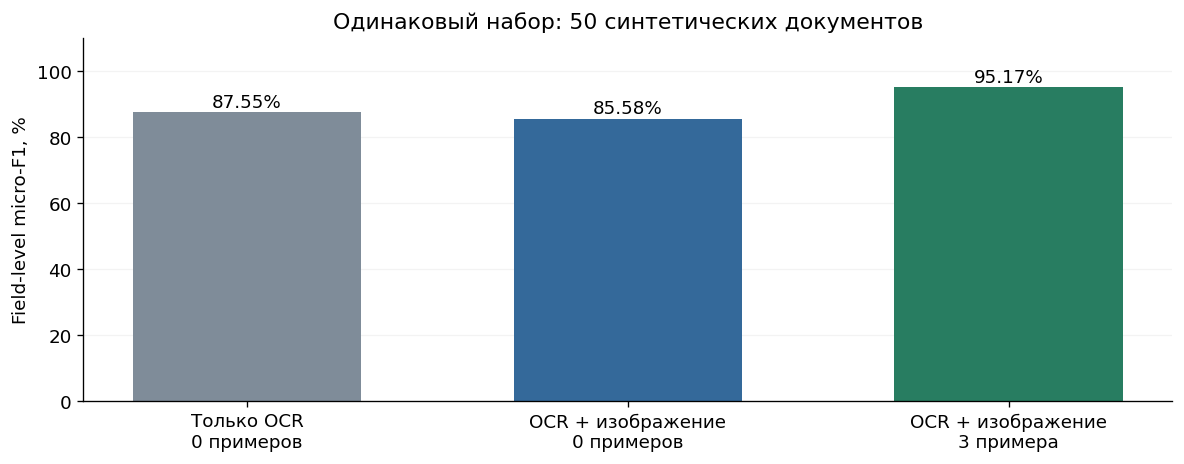

In [4]:
fig,ax=plt.subplots(figsize=(10,4))
labels=['Только OCR\n0 примеров','OCR + изображение\n0 примеров','OCR + изображение\n3 примера']
values=[100*s['field_f1'] for s in modes.values()]
bars=ax.bar(labels,values,color=['#7F8C99','#34699A','#287D61'],width=.6)
for bar,v in zip(bars,values):ax.text(bar.get_x()+bar.get_width()/2,v+1.5,f'{v:.2f}%',ha='center')
ax.set(ylim=(0,110),ylabel='Field-level micro-F1, %',title='Одинаковый набор: 50 синтетических документов')
ax.set_yticks(range(0,101,20));ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)
fig.tight_layout();fig.savefig(WORK/'three_modes_f1.png',bbox_inches='tight');plt.show()


## 3. Количественные эффекты и выводы

Расчёты доверительных интервалов не дублируются. Статистический результат берётся из отчёта отдельного [bootstrap-ноутбука](bootstrap_hypotheses_review.ipynb).

In [5]:
stats=json.loads((WORK/'bootstrap_results.json').read_text())
by_name={x['name']:x for x in stats['results']}
for p,source in zip(paths.values(),stats['sources']):assert hashlib.sha256(p.read_bytes()).hexdigest()==source['sha256']
for h,name in [('H1','H1_fewshot_all_50'),('H2','H2_image_all_50')]:
    report=reports[h];x=by_name[name]
    assert abs(report['delta_f1_pp']-x['delta_f1_pp'])<1e-12
    display(Markdown(f"**{h}, 50 документов:** наблюдаемый прирост micro-F1 **{report['delta_f1_pp']:+.2f} п.п.**"))
    decision='Нижняя граница ДИ выше нуля: численный критерий выполнен на этом наборе.' if x['positive_effect_supported'] else 'Нижняя граница ДИ не выше нуля: положительный эффект статистическим критерием не подтверждён.'
    display(Markdown(decision+' Расчёт ДИ — в отдельном ноутбуке.'))
    print('Успешных пар:',report['paired_successful_documents'],'; прирост на успешных парах:',
          round(report['paired_delta_f1_pp'],2) if report['paired_delta_f1_pp'] is not None else None,'п.п.')
    print('Статусы:',report['statuses'])


**H1, 50 документов:** наблюдаемый прирост micro-F1 **+9.60 п.п.**

Нижняя граница ДИ выше нуля: численный критерий выполнен на этом наборе. Расчёт ДИ — в отдельном ноутбуке.

Успешных пар: 49 ; прирост на успешных парах: 9.14 п.п.
Статусы: {'zero_shot': {'completed': 49, 'incomplete': 1}, 'few_shot_3': {'completed': 50}}


**H2, 50 документов:** наблюдаемый прирост micro-F1 **-1.98 п.п.**

Нижняя граница ДИ не выше нуля: положительный эффект статистическим критерием не подтверждён. Расчёт ДИ — в отдельном ноутбуке.

Успешных пар: 49 ; прирост на успешных парах: -1.45 п.п.
Статусы: {'ocr_only': {'completed': 50}, 'ocr_image': {'completed': 49, 'incomplete': 1}}


## 4. Разбивка по шаблонам

Среднее F1 шаблонов не заменяет общий micro-F1; счётчики сначала суммируются.

In [6]:
def aggregate_f1(rows):
    tp=sum(x['metrics']['counts']['true_positive'] for x in rows)
    fp=sum(x['metrics']['counts']['false_positive'] for x in rows)
    fn=sum(x['metrics']['counts']['false_negative'] for x in rows)
    return 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0
rows=[]
for template in range(1,7):
    a=[x for x in reports['H2']['runs']['ocr_only'] if x['template']==template]
    b=[x for x in reports['H2']['runs']['ocr_image'] if x['template']==template]
    c=[x for x in reports['H1']['runs']['few_shot_3'] if x['template']==template]
    fa,fb,fc=map(aggregate_f1,[a,b,c])
    rows.append({'Шаблон':template,'n':len(a),'OCR-only F1, %':100*fa,'OCR+image F1, %':100*fb,
       '3-shot F1, %':100*fc,'H1 ΔF1, п.п.':100*(fc-fb),'H2 ΔF1, п.п.':100*(fb-fa)})
display(pd.DataFrame(rows).round(2))


,Шаблон,n,"OCR-only F1, %","OCR+image F1, %","3-shot F1, %","H1 ΔF1, п.п.","H2 ΔF1, п.п."
0,1,9,99.52,94.12,100.00,5.88,-5.40
1,2,9,90.87,87.63,92.56,4.93,-3.23
2,3,8,87.50,100.00,81.90,-18.10,12.50
3,4,8,90.86,86.20,97.48,11.27,-4.66
4,5,8,70.77,71.39,100.00,28.61,0.62
5,6,8,93.88,92.46,94.36,1.90,-1.42


## 5. Дополнительные показатели и ограничения

In [7]:
display(pd.DataFrame([{'Режим':label,'CER (среднее)':s['mean_cer'],'WER (среднее)':s['mean_wer'],
    'bbox IoU (отдельно)':s['bbox_mean_iou']} for label,s in modes.items()]).round(4))
display(pd.DataFrame([{'Сравнение':h,'Режим':mode,**usage}
    for h,report in reports.items() for mode,usage in report['usage'].items()]))


,Режим,CER (среднее),WER (среднее),bbox IoU (отдельно)
0,"Только OCR, 0 примеров",0.0134,0.0355,0.5696
1,"OCR + изображение, 0 примеров",0.0265,0.0390,0.5529
2,"OCR + изображение, 3 примера",0.0236,0.0364,0.5745


,Сравнение,Режим,input_tokens,output_tokens,total_tokens
0,H1,zero_shot,775150,802417,1577567
1,H1,few_shot_3,2142300,758164,2900464
2,H2,ocr_only,613980,767336,1381316
3,H2,ocr_image,775150,802417,1577567
